# Некоторые полезные примеры при работе в sklearn.

Мини-справочник по `Pipeline`, `ColumnTransformer`, кастомным трансформерам и не только.

---

**Важно:**

Результаты и доступные параметры могут отличаться в зависимости от версии scikit-learn.

## Версия scikit-learn.

Часть примеров ниже использует API, появившееся в относительно свежих версиях (`sparse_output` у `OneHotEncoder`, `set_output`, актуальный `multi_class` у `LogisticRegression`). Минимально рекомендуемая версия — **1.2+**, всё остальное проверено на **1.5+**.

Если что-то не работает - сначала посмотрите версию.

## Проблема и решение.

Когда мы готовим данные к модели, почти всегда нужно сделать несколько шагов подряд: заполнить пропуски, закодировать категории, отмасштабировать признаки, обучить модель.

Если делать это "руками" - легко ошибиться:

- можно забыть применить ту же обработку к тестовой выборке;
- можно случайно обучить imputer / scaler на тесте -> **утечка данных (data leakage)**;
- при кросс-валидации придётся вручную повторять всю цепочку внутри каждого фолда;
- при подборе гиперпараметров придётся отдельно перебирать параметры препроцессинга и модели.


**Решение - `Pipeline`.**

`Pipeline` - это объект, который хранит **последовательность шагов** и применяет их как единое целое:

```python
Pipeline(steps=[('imputer', ...), ('scaler', ...), ('model', ...)])
```


Что это даёт:

1. **Один `fit` - вся цепочка.** Препроцессинг обучается только на train.
2. **Один `predict` - вся цепочка.** Новые данные автоматически проходят ту же обработку.
3. **Никакой утечки.** Внутри `cross_val_score` и `GridSearchCV` препроцессинг переобучается на каждом фолде.
4. **Единое пространство гиперпараметров.** Доступ к параметрам шагов через `step__param`.

### `ColumnTransformer`.

Разные столбцы требуют разной обработки:
- числовые -> imputer + scaler;
- категориальные -> imputer + one-hot encoder.

`ColumnTransformer` позволяет применить **разные пайплайны к разным группам колонок** и склеить результат.

Рассмотрим далее примеры.

## Пример: предсказание выживания пассажиров.

Соберём полный пайплайн для таблицы с числовыми и категориальными признаками:


ColumnTransformer:

- num: ['pclass', 'age'] -> SimpleImputer(median) -> StandardScaler;
- cat: ['sex', 'embarked'] -> SimpleImputer(most_frequent) -> OneHotEncoder;

        ---> LogisticRegression.

**Что мы тут сделали? Мы к разным типам признаком применили разные преобразования. Потом объединили это и всё вместе подали в логистическую модель.**

Обратите внимание: `SimpleImputer` и `OneHotEncoder` обучаются **внутри** пайплайна, поэтому на тесте и на новых данных они поведут себя корректно.

**То есть:**
"Внутри пайплайна imputer и encoder обучаются только на train — поэтому на тесте и на новых данных применяются те же правила, что выучены на train, без утечки."

**Задача: Предсказание выживания пассажиров Титаника**

Дан DataFrame с пассажирами Титаника, содержащий следующие колонки:

* pclass (числовой) - класс билета (1, 2, 3)
* sex (категориальный) - пол ('male', 'female')
* age (числовой) - возраст (есть пропуски)
* embarked (категориальный) - порт посадки ('S', 'C', 'Q', есть пропуски)
* survived (целевая переменная) - выжил (1) или нет (0)

**Требуется:**

Создать Pipeline, который:

* Для числовых признаков (pclass, age) заполнит пропуски медианой
* Для категориальных признаков (sex, embarked) заполнит пропуски модой и применит OneHotEncoding
* Обучит логистическую регрессию

In [1]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

np.random.seed(42)

# Синтетические данные
n_samples = 100
data = pd.DataFrame({
    'pclass':   np.random.choice([1, 2, 3], n_samples),
    'sex':      np.random.choice(['male', 'female'], n_samples),
    'age':      np.random.normal(30, 10, n_samples).round(),
    'embarked': np.random.choice(['S', 'C', 'Q'], n_samples),
    'survived': np.random.choice([0, 1], n_samples),
})

# Искусственно добавим пропуски
data.loc[0:5, 'age'] = np.nan
data.loc[0:3, 'embarked'] = np.nan

X = data.drop('survived', axis=1)
y = data['survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Признаки
numeric_features     = ['pclass', 'age']
categorical_features = ['sex', 'embarked']

# Отдельные пайплайны для каждой группы
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  OneHotEncoder(handle_unknown='ignore')),
])

# Объединяем через ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
    ]
)

# Финальный пайплайн
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier',   LogisticRegression(random_state=42)),
])

# Обучение и оценка
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

accuracy = (y_pred == y_test).mean()
print(f"Доля правильных ответов: {accuracy:.2f}")

# Предсказание для нового объекта
new_passenger = pd.DataFrame({
    'pclass':   [1],
    'sex':      ['female'],
    'age':      [25],
    'embarked': ['S'],
})

prediction = model.predict(new_passenger)
print(f"Предсказание для нового пассажира: "
      f"{'Выживет' if prediction[0] == 1 else 'Не выживет'}")

Доля правильных ответов: 0.45
Предсказание для нового пассажира: Не выживет


Структура примера выше:

```text
model (Pipeline)
├── preprocessor (ColumnTransformer)
│   ├── num (Pipeline)
│   │   ├── imputer (SimpleImputer)
│   │   └── scaler  (StandardScaler)
│   └── cat (Pipeline)
│       ├── imputer (SimpleImputer)
│       └── onehot  (OneHotEncoder)
└── classifier (LogisticRegression)
```

Как узнать все доступные ключи / параметры / гиперпараметры?

In [2]:
# так :)

for name, value in model.get_params().items():
    print(f"{name}: {value}")

memory: None
steps: [('preprocessor', ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['pclass', 'age']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['sex', 'embarked'])])), ('classifier', LogisticRegression(random_state=42))]
transform_input: None
verbose: False
preprocessor: ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                 

Обратиться к выбранному параметру / гиперпараметру можно следующим образом.

In [3]:
print(model.get_params()['preprocessor__num__imputer__strategy'])

median


In [4]:
# Или даже можно поменять это, если захотим.

# model.set_params(preprocessor__num__imputer__strategy='mean')
# print(model.get_params()['preprocessor__num__imputer__strategy'])
# Значение будет "mean" :)

Путь к вложенному параметру / гиперпараметру читается **слева направо, от внешнего шага к внутреннему**, а уровни разделяются двойным подчёркиванием `__`:

`имя_шага__имя_вложенного_шага__имя_параметра`


Для пайплайна из примера выше:

| Что хотим изменить | Ключ |
|---|---|
| `C` у логистической регрессии | `classifier__C` |
| стратегию imputer'а в числовом блоке | `preprocessor__num__imputer__strategy` |
| стратегию imputer'а в категориальном блоке | `preprocessor__cat__imputer__strategy` |
| `with_mean` у scaler'а в числовом блоке | `preprocessor__num__scaler__with_mean` |
| `handle_unknown` у one-hot encoder'а | `preprocessor__cat__onehot__handle_unknown` |

**Вопрос:** что произойдёт, если мы подадим на вход пассажира с незнакомым значением `embarked`, например 'X'? Почему пайплайн не упадёт?

**Ответ:** OneHotEncoder(handle_unknown='ignore') закодирует такое значение всеми нулями - модель просто не увидит сигнала от этой категории, но ошибки не будет.

## Параметры вложенных шагов.

`Pipeline` умеет "пробрасывать" параметры вложенных объектов.
Ключ формируется как `имя_шага__имя_параметра` (двойное подчёркивание).

Это то, что использует `GridSearchCV`:

```python
param_grid = {
    'classifier__C':        [0.1, 1.0, 10.0],
    'preprocessor__num__imputer__strategy': ['mean', 'median'],
}

In [5]:
# Ниже - как просто посмотреть все доступные параметры через get_params().

Результат `get_params()` на маленьком примере.

```python
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Маленький пайплайн: масштабирование + SVM
pipe = Pipeline([('scaler', StandardScaler()), ('svc', SVC(C=1.0))])

# Все параметры (включая вложенные)
all_params = pipe.get_params()

# Конкретные гиперпараметры
print(f"SVC C parameter:              {all_params['svc__C']}")
print(f"Scaler with_mean parameter:   {all_params['scaler__with_mean']}")
print()

# Полный список
for param_name, param_value in all_params.items():
    print(f"{param_name}: {param_value}")
```

Вот в виде кода:

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Маленький пайплайн: масштабирование + SVM
pipe = Pipeline([('scaler', StandardScaler()), ('svc', SVC(C=1.0))])

# Все параметры (включая вложенные)
all_params = pipe.get_params()

# Конкретные гиперпараметры
print(f"SVC C parameter:              {all_params['svc__C']}")
print(f"Scaler with_mean parameter:   {all_params['scaler__with_mean']}")
print()

# Полный список
for param_name, param_value in all_params.items():
    print(f"{param_name}: {param_value}")

SVC C parameter:              1.0
Scaler with_mean parameter:   True

memory: None
steps: [('scaler', StandardScaler()), ('svc', SVC())]
transform_input: None
verbose: False
scaler: StandardScaler()
svc: SVC()
scaler__copy: True
scaler__with_mean: True
scaler__with_std: True
svc__C: 1.0
svc__break_ties: False
svc__cache_size: 200
svc__class_weight: None
svc__coef0: 0.0
svc__decision_function_shape: ovr
svc__degree: 3
svc__gamma: scale
svc__kernel: rbf
svc__max_iter: -1
svc__probability: False
svc__random_state: None
svc__shrinking: True
svc__tol: 0.001
svc__verbose: False


Обратите внимание: имена вроде svc__C и scaler__with_mean - это и есть тот самый синтаксис с двойным подчёркиванием, который используется в GridSearchCV и set_params.

## Что запомнить?

- `Pipeline` - это единый объект, который гарантирует, что препроцессинг и модель обучаются и применяются согласованно.
- `ColumnTransformer` позволяет применять разные преобразования к разным колонкам и легко расширяется новыми блоками.
- Доступ к параметрам вложенных шагов - через `step__param` (двойное подчёркивание).
- `Pipeline` + `GridSearchCV` + `cross_val_score` - стандартный рецепт корректной валидации без утечек.
- Пайплайн удобно сохранять целиком (`joblib`), чтобы использовать в проде как есть.

## StandardScaler: вручную vs sklearn - сравнение.

Давайте сравним вручную написанный StandardScaler и стандартную реализацию в sklearn.

In [7]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Исходные данные (3 признака, 5 объектов)
X = np.array([
    [1.0,  200.0, 0.5],
    [2.0,  300.0, 1.5],
    [3.0,  400.0, 2.5],
    [4.0,  500.0, 3.5],
    [5.0,  600.0, 4.5],
])

# Вручную: (x - mean) / std
mean = X.mean(axis=0)
std  = X.std(axis=0)  # по умолчанию ddof=0 (как в sklearn)
X_manual = (X - mean) / std

# Автоматически через sklearn
sc = StandardScaler()
X_sklearn = sc.fit_transform(X)

# Сравнение:
print("Ручной mean:   ", mean)
print("sklearn mean_: ", sc.mean_)
print("Ручной std:    ", std)
print("sklearn scale_:", sc.scale_)
print()
print("Макс. абсолютная разница:", np.abs(X_manual - X_sklearn).max())
print("Матрицы идентичны:", np.allclose(X_manual, X_sklearn))

Ручной mean:    [  3.  400.    2.5]
sklearn mean_:  [  3.  400.    2.5]
Ручной std:     [  1.41421356 141.42135624   1.41421356]
sklearn scale_: [  1.41421356 141.42135624   1.41421356]

Макс. абсолютная разница: 0.0
Матрицы идентичны: True


## Про наследование (и почему это важно) классов в sklearn.

Рассмотрим примеры задач на sklearn:

**Задача:** Создать свой скейлер "WinsorizedScaler", который будет ограничивать значения признаков заданными перцентилями (метод винсоризации), а затем применять стандартизацию.

**Нужно:**

* Наследоваться от BaseEstimator и TransformerMixin
* Реализовать методы fit и transform
* Применить скейлер к данным

In [8]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [9]:
class WinsorizedScaler(BaseEstimator, TransformerMixin):
    """
    Скейлер, который:
    1. Обрезает выбросы до заданных перцентилей (по умолчанию 5-й и 95-й)
    2. Стандартизирует полученные данные (вычитает среднее, делит на std)
    """

    def __init__(self, lower_percentile=5, upper_percentile=95):
        self.lower_percentile = lower_percentile
        self.upper_percentile = upper_percentile
        self.lower_bounds_ = None
        self.upper_bounds_ = None
        self.mean_ = None
        self.std_ = None

    def fit(self, X, y=None):
        """
        Вычисляем границы для обрезания и параметры стандартизации
        """
        X = np.array(X)
        self.lower_bounds_ = np.percentile(X, self.lower_percentile, axis=0)
        self.upper_bounds_ = np.percentile(X, self.upper_percentile, axis=0)

        X_clipped = np.clip(X, self.lower_bounds_, self.upper_bounds_)
        self.mean_ = np.mean(X_clipped, axis=0)
        self.std_ = np.std(X_clipped, axis=0)

        return self

    def transform(self, X):
        """
        Обрезаем выбросы и стандартизируем
        """
        X = np.array(X)
        X_clipped = np.clip(X, self.lower_bounds_, self.upper_bounds_)
        X_scaled = (X_clipped - self.mean_) / (self.std_ + 1e-10)

        return X_scaled

In [10]:
np.random.seed(42)
n_samples = 1000

X = np.random.normal(0, 1, (n_samples, 2))
X[:10, 0] = np.random.uniform(10, 20, 10)
X[:10, 1] = np.random.uniform(-20, -10, 10)

y = (X[:, 0] + X[:, 1] + np.random.normal(0, 1, n_samples) > 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
pipeline = Pipeline([
    ('winsorized_scaler', WinsorizedScaler(lower_percentile=5, upper_percentile=95)),
    ('classifier', LogisticRegression())
])

pipeline.fit(X_train, y_train)

train_score = pipeline.score(X_train, y_train)
test_score = pipeline.score(X_test, y_test)

print(f"Точность на train: {train_score:.3f}")
print(f"Точность на test: {test_score:.3f}")

Точность на train: 0.819
Точность на test: 0.800


---

---

---

In [12]:
class WinsorizedScaler_without_TransformerMixin:
    """
    Скейлер, который:
    1. Обрезает выбросы до заданных перцентилей (по умолчанию 5-й и 95-й)
    2. Стандартизирует полученные данные (вычитает среднее, делит на std)
    """

    def __init__(self, lower_percentile=5, upper_percentile=95):
        self.lower_percentile = lower_percentile
        self.upper_percentile = upper_percentile
        self.lower_bounds_ = None
        self.upper_bounds_ = None
        self.mean_ = None
        self.std_ = None

    def fit(self, X, y=None):
        """
        Вычисляем границы для обрезания и параметры стандартизации
        """
        X = np.array(X)
        self.lower_bounds_ = np.percentile(X, self.lower_percentile, axis=0)
        self.upper_bounds_ = np.percentile(X, self.upper_percentile, axis=0)

        X_clipped = np.clip(X, self.lower_bounds_, self.upper_bounds_)
        self.mean_ = np.mean(X_clipped, axis=0)
        self.std_ = np.std(X_clipped, axis=0)

        return self

    def transform(self, X):
        """
        Обрезаем выбросы и стандартизируем
        """
        X = np.array(X)
        X_clipped = np.clip(X, self.lower_bounds_, self.upper_bounds_)
        X_scaled = (X_clipped - self.mean_) / (self.std_ + 1e-10)

        return X_scaled

In [13]:
pipeline = Pipeline([
    ('winsorized_scaler', WinsorizedScaler_without_TransformerMixin(lower_percentile=5, upper_percentile=95)),
    ('classifier', LogisticRegression())
])

pipeline.fit(X_train, y_train)

train_score = pipeline.score(X_train, y_train)
test_score = pipeline.score(X_test, y_test)

print(f"Точность на train: {train_score:.3f}")
print(f"Точность на test: {test_score:.3f}")

Точность на train: 0.819
Точность на test: 0.800


In [14]:
scaler_without_TransformerMixin = WinsorizedScaler_without_TransformerMixin()

# ОШИБКА: нет метода fit_transform
try:
    X_transformed = scaler_without_TransformerMixin.fit_transform(X)
except AttributeError as e:
    print(f"Ошибка: {e}")
    # Нужно писать две строки:
    scaler_without_TransformerMixin.fit(X)
    X_transformed = scaler_without_TransformerMixin.transform(X)

Ошибка: 'WinsorizedScaler_without_TransformerMixin' object has no attribute 'fit_transform'


In [15]:
class WinsorizedScaler_with_TransformerMixin(TransformerMixin):
    """
    Скейлер, который:
    1. Обрезает выбросы до заданных перцентилей (по умолчанию 5-й и 95-й)
    2. Стандартизирует полученные данные (вычитает среднее, делит на std)
    """

    def __init__(self, lower_percentile=5, upper_percentile=95):
        self.lower_percentile = lower_percentile
        self.upper_percentile = upper_percentile
        self.lower_bounds_ = None
        self.upper_bounds_ = None
        self.mean_ = None
        self.std_ = None

    def fit(self, X, y=None):
        """
        Вычисляем границы для обрезания и параметры стандартизации
        """
        X = np.array(X)
        self.lower_bounds_ = np.percentile(X, self.lower_percentile, axis=0)
        self.upper_bounds_ = np.percentile(X, self.upper_percentile, axis=0)

        X_clipped = np.clip(X, self.lower_bounds_, self.upper_bounds_)
        self.mean_ = np.mean(X_clipped, axis=0)
        self.std_ = np.std(X_clipped, axis=0)

        return self

    def transform(self, X):
        """
        Обрезаем выбросы и стандартизируем
        """
        X = np.array(X)
        X_clipped = np.clip(X, self.lower_bounds_, self.upper_bounds_)
        X_scaled = (X_clipped - self.mean_) / (self.std_ + 1e-10)

        return X_scaled

In [16]:
pipeline = Pipeline([
    ('winsorized_scaler', WinsorizedScaler_with_TransformerMixin(lower_percentile=5, upper_percentile=95)),
    ('classifier', LogisticRegression())
])

pipeline.fit(X_train, y_train)

train_score = pipeline.score(X_train, y_train)
test_score = pipeline.score(X_test, y_test)

print(f"Точность на train: {train_score:.3f}")
print(f"Точность на test: {test_score:.3f}")

Точность на train: 0.819
Точность на test: 0.800


In [17]:
scaler_with_TransformerMixin = WinsorizedScaler_with_TransformerMixin()

# ВСЁ ОК: есть метод fit_transform
try:
    X_transformed = scaler_with_TransformerMixin.fit_transform(X)
except AttributeError as e:
    print(f"Ошибка: {e}")
    # Нужно писать две строки:
    scaler_with_TransformerMixin.fit(X)
    X_transformed = scaler_with_TransformerMixin.transform(X)

**TransformerMixin**

**Добавляет метод fit_transform(), который автоматически вызывает fit(X).transform(X).**


---

---

---

In [18]:
from sklearn.model_selection import GridSearchCV

In [19]:
class WinsorizedScaler_without_BaseEstimator:
    """
    Скейлер, который:
    1. Обрезает выбросы до заданных перцентилей (по умолчанию 5-й и 95-й)
    2. Стандартизирует полученные данные (вычитает среднее, делит на std)
    """

    def __init__(self, lower_percentile=5, upper_percentile=95):
        self.lower_percentile = lower_percentile
        self.upper_percentile = upper_percentile
        self.lower_bounds_ = None
        self.upper_bounds_ = None
        self.mean_ = None
        self.std_ = None

    def fit(self, X, y=None):
        """
        Вычисляем границы для обрезания и параметры стандартизации
        """
        X = np.array(X)
        self.lower_bounds_ = np.percentile(X, self.lower_percentile, axis=0)
        self.upper_bounds_ = np.percentile(X, self.upper_percentile, axis=0)

        X_clipped = np.clip(X, self.lower_bounds_, self.upper_bounds_)
        self.mean_ = np.mean(X_clipped, axis=0)
        self.std_ = np.std(X_clipped, axis=0)

        return self

    def transform(self, X):
        """
        Обрезаем выбросы и стандартизируем
        """
        X = np.array(X)
        X_clipped = np.clip(X, self.lower_bounds_, self.upper_bounds_)
        X_scaled = (X_clipped - self.mean_) / (self.std_ + 1e-10)

        return X_scaled

    # Добавляем метод score (просто заглушка)
    def score(self, X, y=None):
        return 0.0

In [20]:
pipeline = Pipeline([
    ('winsorized_scaler', WinsorizedScaler_without_BaseEstimator(lower_percentile=5, upper_percentile=95)),
    ('classifier', LogisticRegression())
])

pipeline.fit(X_train, y_train)

train_score = pipeline.score(X_train, y_train)
test_score = pipeline.score(X_test, y_test)

print(f"Точность на train: {train_score:.3f}")
print(f"Точность на test: {test_score:.3f}")

Точность на train: 0.819
Точность на test: 0.800


In [21]:
scaler_without_BaseEstimator = WinsorizedScaler_without_BaseEstimator()

# Попытка использовать GridSearchCV
param_grid = {'lower_percentile': [1, 5, 10], 'upper_percentile': [90, 95, 99]}

try:
    grid_search = GridSearchCV(scaler_without_BaseEstimator, param_grid, cv=5)
    grid_search.fit(X, y)  # ОШИБКА!
except Exception as e:
    print(f"Ошибка: {e}")
    # Scaler error: Этот объект не имеет метода get_params()

Ошибка: Cannot clone object '<__main__.WinsorizedScaler_without_BaseEstimator object at 0x792b4ea24410>' (type <class '__main__.WinsorizedScaler_without_BaseEstimator'>): it does not seem to be a scikit-learn estimator as it does not implement a 'get_params' method.


In [22]:
class WinsorizedScaler_CORRECT(BaseEstimator, TransformerMixin):
    """
    Скейлер, который:
    1. Обрезает выбросы до заданных перцентилей (по умолчанию 5-й и 95-й)
    2. Стандартизирует полученные данные (вычитает среднее, делит на std)
    """

    def __init__(self, lower_percentile=5, upper_percentile=95):
        self.lower_percentile = lower_percentile
        self.upper_percentile = upper_percentile
        self.lower_bounds_ = None
        self.upper_bounds_ = None
        self.mean_ = None
        self.std_ = None

    def fit(self, X, y=None):
        """
        Вычисляем границы для обрезания и параметры стандартизации
        """
        X = np.array(X)
        self.lower_bounds_ = np.percentile(X, self.lower_percentile, axis=0)
        self.upper_bounds_ = np.percentile(X, self.upper_percentile, axis=0)

        X_clipped = np.clip(X, self.lower_bounds_, self.upper_bounds_)
        self.mean_ = np.mean(X_clipped, axis=0)
        self.std_ = np.std(X_clipped, axis=0)

        return self

    def transform(self, X):
        """
        Обрезаем выбросы и стандартизируем
        """
        X = np.array(X)
        X_clipped = np.clip(X, self.lower_bounds_, self.upper_bounds_)
        X_scaled = (X_clipped - self.mean_) / (self.std_ + 1e-10)

        return X_scaled

    # Добавляем метод score (просто заглушка)
    def score(self, X, y=None):
        return 0.0

In [23]:
# ВСЁ РАБОТАЕТ :)
scaler_correct = WinsorizedScaler_CORRECT()

# Есть fit_transform
X_transformed = scaler_correct.fit_transform(X)

# Работает с GridSearchCV
param_grid = {
    'lower_percentile': [1, 5, 10],
    'upper_percentile': [90, 95, 99]
}
grid_search = GridSearchCV(scaler_correct, param_grid, cv=5)
grid_search.fit(X, y)  # Успех :)

# Работает в пайплайне
pipeline = Pipeline([
    ('scaler', scaler_correct),
    ('classifier', LogisticRegression())
])
pipeline.fit(X, y)  # Успех :)

print("Все работает отлично!")

Все работает отлично!


In [24]:
# Создаем пайплайн
pipeline = Pipeline([
    ('scaler', WinsorizedScaler_CORRECT()),
    ('classifier', LogisticRegression())
])

# GridSearch для пайплайна (а не для скейлера)
param_grid_pipeline = {
    'scaler__lower_percentile': [1, 5, 10],
    'scaler__upper_percentile': [90, 95, 99],
    'classifier__C': [0.1, 1.0, 10.0]
}

grid_pipeline = GridSearchCV(pipeline, param_grid_pipeline, cv=5)
grid_pipeline.fit(X, y)  # Работает :)
print("GridSearch для пайплайна работает правильно!")
print(f"Лучшие параметры: {grid_pipeline.best_params_}")

GridSearch для пайплайна работает правильно!
Лучшие параметры: {'classifier__C': 0.1, 'scaler__lower_percentile': 10, 'scaler__upper_percentile': 90}


---

In [25]:
from sklearn.base import clone

scaler = WinsorizedScaler()
scaler_without_BaseEstimator = WinsorizedScaler_without_BaseEstimator()

# Без наследования - clone может сломаться
try:
    scaler_without_BaseEstimator_clone = clone(scaler_without_BaseEstimator)
except Exception as e:
    print(f"Ошибка clone без наследования: {e}")

# С наследованием - работает
scaler_with_base_clone = clone(scaler)
print("clone с BaseEstimator работает!")

Ошибка clone без наследования: Cannot clone object '<__main__.WinsorizedScaler_without_BaseEstimator object at 0x792b4ea25bd0>' (type <class '__main__.WinsorizedScaler_without_BaseEstimator'>): it does not seem to be a scikit-learn estimator as it does not implement a 'get_params' method.
clone с BaseEstimator работает!


**BaseEstimator**

**Этот класс предоставляет две важные функции:**

* **Автоматически добавляет методы get_params() и set_params() - необходимые для работы с GridSearchCV.**
* **Обеспечивает совместимость с пайплайнами scikit-learn.**

**Что еще дает наследование?**

* Совместимость с clone() - scikit-learn может создавать копии объектов.
* Правильная работа с set_params() - можно менять параметры после создания.
* Документация - объекты правильно идентифицируются как трансформеры.
* Валидация - некоторые проверки выполняются автоматически.

**Итог:**

**BaseEstimator и TransformerMixin - это "контракт", который говорит scikit-learn: "Я такой же трансформер, как и все остальные, работай со мной стандартными методами". Без них наш класс будет обычным Python-классом, несовместимым с экосистемой scikit-learn.**

## Дополнительные полезные / интересные штуки из sklearn.

### FunctionTransformer - создание трансформеров из функций.

In [26]:
import numpy as np
from sklearn.preprocessing import FunctionTransformer

# Можно создать трансформер из любой функции
log_transformer = FunctionTransformer(np.log1p, validate=True)  # log(1+x)
sqrt_transformer = FunctionTransformer(np.sqrt, validate=True)

# Или даже из своей функции с параметрами
def winsorize(X, lower=0.05, upper=0.95):
    l = np.percentile(X, lower*100, axis=0)
    u = np.percentile(X, upper*100, axis=0)
    return np.clip(X, l, u)

winsorizer = FunctionTransformer(winsorize, kw_args={'lower': 0.05, 'upper': 0.95})

### FeatureUnion - объединение разных признаков.

In [27]:
from sklearn.pipeline import FeatureUnion
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest

# Объединяем разные наборы признаков
feature_union = FeatureUnion([
    ('pca', PCA(n_components=2)),  # главные компоненты
    ('best', SelectKBest(k=3))  # отбор признаков
])

### Memory - кеширование промежуточных результатов.

In [28]:
from joblib import Memory

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Кешируем результаты долгих вычислений
memory = Memory(location='cachedir', verbose=0)

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=10)),
    ('classifier', LogisticRegression())
], memory=memory)  # Теперь повторные запуски должны быть быстрее
# это работает не всегда, но всё же

### Pipeline с условиями - выбор шага в зависимости от данных.

In [29]:
from sklearn.base import BaseEstimator, TransformerMixin

class ConditionalTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, transformer_if, condition_func):
        self.transformer_if = transformer_if
        self.condition_func = condition_func

    def fit(self, X, y=None):
        if self.condition_func(X):
            self.transformer_if.fit(X, y)
        return self

    def transform(self, X):
        if hasattr(self, 'transformer_if'):
            return self.transformer_if.transform(X)
        return X

# Используем PCA только если много признаков
pipeline = Pipeline([
    ('conditional_pca', ConditionalTransformer(
        PCA(n_components=2),
        condition_func=lambda X: X.shape[1] > 10
    ))
])

### Интересный трюк с set_output.

In [30]:
# Современные версии sklearn могут возвращать pandas DataFrame

# import pandas as pd
# from sklearn.preprocessing import StandardScaler

# scaler = StandardScaler().set_output(transform="pandas")
# X_scaled = scaler.fit_transform(X_df)  # Возвращает DataFrame с сохранением колонок :)

### Пайплайн с несколькими моделями.

In [31]:
# from sklearn.ensemble import VotingClassifier

# # Ансамбль из разных моделей
# ensemble = VotingClassifier([
#     ('lr', LogisticRegression()),
#     ('rf', RandomForestClassifier()),
#     ('svm', SVC(probability=True))
# ], voting='soft')

# # Можно оптимизировать всё сразу
# param_grid = {
#     'lr__C': [0.1, 1.0],
#     'rf__n_estimators': [50, 100],
#     'svm__C': [0.1, 1.0]
# }

На самом деле таких примеров очень и очень много в sklearn... Я даже далеко не всё сюда внёс. Остальное можно и нужно в документациях смотреть. Ну и у ИИ спрашивать :)

**Важно здесь то, что результаты сильно могут зависеть от версии sklearn.**

## Прочее :)

И вот ещё из интересного ;)

Многослойный перцептрон (MLP) в scikit-learn:

Scikit-learn предлагает два класса для нейронных сетей:

* MLPClassifier — для классификации;
* MLPRegressor — для регрессии.

### Пример для классификации.

In [32]:
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Загружаем данные
iris = load_iris()
X, y = iris.data, iris.target

# Важно! Нейросети чувствительны к масштабу данных
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Обучаем нейросеть
mlp = MLPClassifier(
    hidden_layer_sizes=(10, 5),  # два скрытых слоя: 10 и 5 нейронов
    activation='relu',           # функция активации
    solver='adam',               # оптимизатор
    max_iter=1000,               # максимальное число эпох
    random_state=42
)

mlp.fit(X_scaled, y)
print(f"Точность: {mlp.score(X_scaled, y):.3f}")

Точность: 0.980


### Пример для регрессии.

In [33]:
from sklearn.neural_network import MLPRegressor
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Данные о недвижимости
housing = fetch_california_housing()
X, y = housing.data, housing.target
print('train shape:', X.shape)

# Масштабирование критически важно!
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Создаем регрессор
regressor = MLPRegressor(
    hidden_layer_sizes=(100, 50),  # два слоя
    activation='relu',
    solver='adam',
    max_iter=500,
    early_stopping=True,           # останавливаемся, если перестало улучшаться
    validation_fraction=0.1,       # 10% данных для валидации
    random_state=42
)

regressor.fit(X_scaled, y)
y_pred = regressor.predict(X_scaled)
print(f"MSE: {mean_squared_error(y, y_pred):.4f}")

train shape: (20640, 8)
MSE: 0.2408


Количество слоёв: 3
Форма / размерность весов первого слоя: (8, 100)
Форма / раазмерность смещений первого слоя: (100,)


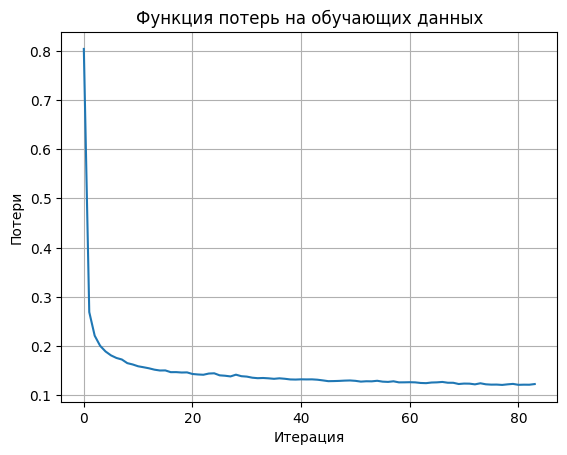

In [34]:
# После обучения можно посмотреть на веса
print(f"Количество слоёв: {len(regressor.coefs_)}")
print(f"Форма / размерность весов первого слоя: {regressor.coefs_[0].shape}")
print(f"Форма / раазмерность смещений первого слоя: {regressor.intercepts_[0].shape}")

# Кривая обучения
plt.plot(regressor.loss_curve_)
plt.title('Функция потерь на обучающих данных')
plt.xlabel('Итерация')
plt.ylabel('Потери')
plt.grid(True)
plt.show()

**Но на больших датасетах и задачах лучше использовать PyTorch / TensorFlow или прочее.**

## Бонус.

**Бонус: Restricted Boltzmann Machine.**

В sklearn есть и более экзотические нейросети, например BernoulliRBM.

In [35]:
# from sklearn.neural_network import BernoulliRBM
# from sklearn.pipeline import Pipeline
# from sklearn.linear_model import LogisticRegression

# # RBM для извлечения признаков + классификатор
# rbm = BernoulliRBM(n_components=100, learning_rate=0.06, n_iter=20)  # unsupervised learning
# logistic = LogisticRegression(C=1000)

# classifier = Pipeline([('rbm', rbm), ('logistic', logistic)])
# classifier.fit(X_train, y_train)

In [36]:
### rbm = BernoulliRBM()
### rbm.fit(X)

## Итог.

scikit-learn — это не только какие-то "скромные" модели, но и **целый мир** алгоритмов, включая нейросети :)

Это и многое другое в scikit-learn изучайте на их [официальном сайте](https://scikit-learn.org/stable).

Спасибо и успехов :)

## Полезные ссылки.

**Основное из этого ноутбука:**

- [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
- [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html)
- [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)
- [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

**Кастомные трансформеры и совместимость:**

- [BaseEstimator](https://scikit-learn.org/stable/modules/generated/sklearn.base.BaseEstimator.html)
- [TransformerMixin](https://scikit-learn.org/stable/modules/generated/sklearn.base.TransformerMixin.html)
- [Rolling your own estimator](https://scikit-learn.org/stable/developers/develop.html)
- [clone](https://scikit-learn.org/stable/modules/generated/sklearn.base.clone.html)

**Подбор и валидация:**

- [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
- [cross_val_score](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
- [Nested vs non-nested CV](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html)

**Разное из "дополнительных штук":**

- [FunctionTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.FunctionTransformer.html)
- [FeatureUnion](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.FeatureUnion.html)
- [set_output API](https://scikit-learn.org/stable/auto_examples/miscellaneous/plot_set_output.html)
- [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) / [MLPRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html)
- [BernoulliRBM](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.BernoulliRBM.html)

**Общее:**

- [User Guide](https://scikit-learn.org/stable/user_guide.html)
- [API Reference](https://scikit-learn.org/stable/modules/classes.html)
- [Release notes](https://scikit-learn.org/stable/whats_new.html) - сюда смотреть, когда "внезапно сломалось после обновления"